In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import differential_evolution, minimize
from scipy.spatial import ConvexHull, QhullError

plt.style.use(style="seaborn-v0_8-whitegrid")
np.set_printoptions(precision=4, suppress=True)

In [8]:
from __future__ import annotations
from numpy.typing import NDArray

In [11]:
def jones_ar_coefficients(p: int, rng: np.random.Generator | int | None = None, *, return_pacf: bool = False):
    if not isinstance(p, (int, np.integer)) or p < 1:
        raise ValueError(f"p must be a positive integer, got {p}")
    generator = np.random.default_rng(rng)
    k = np.arange(1, p + 1)
    a = (k + 1) // 2
    b = k // 2 + 1
    beta_draws = generator.beta(a, b)
    pacf = 2.0 * beta_draws - 1.0
    phi = np.array([pacf[0]], dtype=float)
    for order in range(2, p + 1):
        reflection_coeff = pacf[order - 1]
        previous_phi = phi
        phi = np.empty(order, dtype=float)
        phi[:-1] = (previous_phi - reflection_coeff * previous_phi[::-1])
        phi[-1] = reflection_coeff
    if return_pacf:
        return phi, pacf
    return phi

def simulate_uniform_ar(phi, sample_size: int, burnin: int=500, half_width=1.0, rng=None):
    phi = np.asarray(phi, dtype=float)
    if phi.ndim != 1 or len(phi) == 0:
        raise ValueError("phi must be a nonempty one-dimensional coefficient vector")
    if not isinstance(sample_size, (int, np.integer)) or sample_size < 1:
        raise ValueError("sample_size must be a positive integer")
    if not isinstance(burnin, (int, np.integer)) or burnin < 0:
        raise ValueError("burnin must be a non-negative integer")
    if half_width <= 0:
        raise ValueError("half_width must be a positive number")
    generator = np.random.default_rng(rng)
    order = len(phi)
    total_length = burnin + order + sample_size
    innovations = generator.uniform(-half_width, half_width, size=total_length)
    series = np.zeros(total_length, dtype=float)
    for t in range(order, total_length):
        recent_values = series[t - np.arange(1, order + 1)]
        series[t] = phi @ recent_values + innovations[t]
    return series[burnin + order:]

phi: [-0.5571]


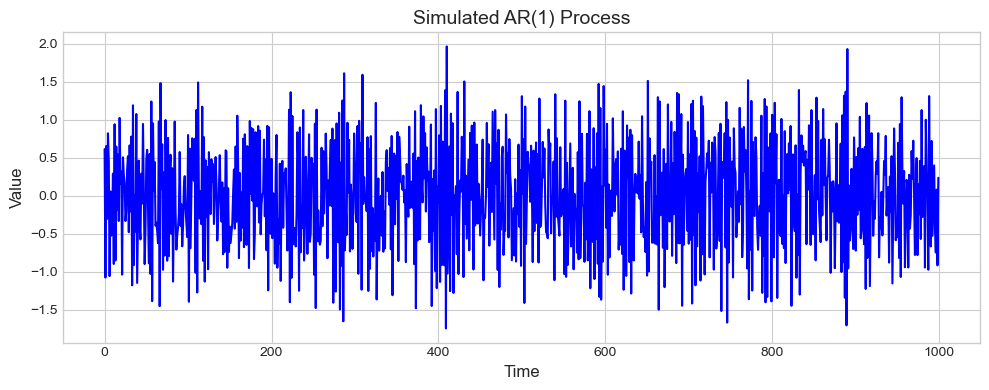

In [15]:
p = 1
coefficient_seed = 42
process_seed = 20260806
sample_size = 1000
burnin = 500
innovations_half_width = 1.0

phi = jones_ar_coefficients(p, rng=coefficient_seed, return_pacf=False)
ar_series = simulate_uniform_ar(phi, sample_size, burnin, innovations_half_width, rng=process_seed)

print("phi:", phi)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(ar_series, color="blue", linewidth=1.5)
ax.set_title(f"Simulated AR({p}) Process", fontsize=14)
ax.set_xlabel("Time", fontsize=12)
ax.set_ylabel("Value", fontsize=12)
plt.tight_layout()
plt.show()

In [16]:
def ar_impulse_response(phi, maximum_lag):
    phi = np.asarray(phi, dtype=float)
    order = len(phi)
    psi = np.zeros(maximum_lag + 1)
    psi[0] = 1.0
    for lag in range(1, maximum_lag + 1):
        psi[lag] = sum(phi[j - 1] * psi[lag - j] for j in range(1, min(order, lag) + 1))
    return psi

In [ ]:
# FUNCTION: ar_window_zonoid_generators
# Assemble the generator matrix G_k for a k-dimensional lag-window support.
# Column j is a times the impulse-response pattern caused by innovation Z_(t-j).
def ar_window_zonoid_generators(phi, embedding_dimension, history, half_width=1.0):
    """Columns are g_j^(k)=a(psi_j, psi_{j-1}, ..., psi_{j-k+1}) in thesis convention."""
    k = int(embedding_dimension)
    if k < 1 or history < 0 or half_width <= 0:
        raise ValueError("Require k >= 1, history >= 0, and half_width > 0.")

    psi = ar_impulse_response(phi, history)
    generators = np.zeros((k, history + 1))
    for innovation_lag in range(history + 1):
        for coordinate in range(k):
            # Translate innovation time and window coordinate into an impulse-response lag.
            response_lag = innovation_lag - coordinate
            if response_lag >= 0:
                # Store this innovation's scaled effect on this window coordinate.
                generators[coordinate, innovation_lag] = half_width * psi[response_lag]
    # Discard numerically zero generator columns before later optimization.
    return generators[:, np.linalg.norm(generators, axis=0) > 1e-13]


# FUNCTION: zonotope_directional_width
# Evaluate w_G(u)=2*sum_j |<g_j,u>| without constructing zonotope vertices.
def zonotope_directional_width(generators, u):
    return float(2.0 * np.sum(np.abs(np.asarray(generators).T @ np.asarray(u))))


In [4]:
# READING GUIDE
# Numerically minimize the directional width over the unit sphere.
# Hyperspherical angles automatically enforce the unit-length constraint on u.
# Differential evolution performs a global search; Powell optionally polishes its best point.
# Known AR recurrence directions are checked explicitly because the nonsmooth objective can hide them.
# The returned dictionary records the minimum, its direction, optimizer status, and winning source.

# FUNCTION: angles_to_unit_vector
# Convert k-1 hyperspherical angles into a unit vector in R^k.
def angles_to_unit_vector(theta, k):
    """Standard hyperspherical coordinates in R^k."""
    if k == 1:
        return np.ones(1)
    theta = np.asarray(theta)
    u = np.empty(k)
    # Track the product of preceding sine factors in hyperspherical coordinates.
    sine_product = 1.0
    for j in range(k - 1):
        u[j] = sine_product * np.cos(theta[j])
        sine_product *= np.sin(theta[j])
    u[-1] = sine_product
    return u


# FUNCTION: _best_candidate_width
# Evaluate a supplied finite list of directions and retain the narrowest valid one.
def _best_candidate_width(generators, candidate_directions):
    if not candidate_directions:
        return None
    best_width = np.inf
    best_direction = None
    for candidate in candidate_directions:
        candidate = np.asarray(candidate, dtype=float)
        norm = np.linalg.norm(candidate)
        if norm <= 0:
            continue
        direction = candidate / norm
        width = zonotope_directional_width(generators, direction)
        if width < best_width:
            best_width = width
            best_direction = direction
    if best_direction is None:
        return None
    return best_width, best_direction


# FUNCTION: estimate_minimum_zonotope_width
# Minimize population zonotope width over all unit directions.
# Return the best width/direction from global search, local polishing, or exact candidates.
def estimate_minimum_zonotope_width(
    generators, seed=0, de_maxiter=80, de_popsize=8, polish=True,
    candidate_directions=None,
):
    generators = np.asarray(generators, dtype=float)
    k = generators.shape[0]
    if k == 1:
        return {
            "m_hat": zonotope_directional_width(generators, np.ones(1)),
            "u_hat": np.ones(1),
            "global_success": True,
            "local_success": True,
            "source": "exact_1d",
        }

    # Use standard angle bounds that cover the full unit sphere.
    bounds = [(0.0, np.pi)] * (k - 2) + [(0.0, 2.0 * np.pi)]
    objective = lambda theta: zonotope_directional_width(
        generators, angles_to_unit_vector(theta, k)
    )
    global_result = differential_evolution(
        objective, bounds=bounds, seed=seed, maxiter=de_maxiter,
        popsize=de_popsize, tol=1e-7, updating="immediate", workers=1, polish=False
    )
    # Start from the globally searched angles and objective value.
    best_x, best_fun = global_result.x, global_result.fun
    best_direction = angles_to_unit_vector(best_x, k)
    source = "optimizer"

    local_success = True
    if polish:
        local_result = minimize(
            objective, best_x, method="Powell", bounds=bounds,
            options={"xtol": 1e-9, "ftol": 1e-9, "maxiter": 1_000},
        )
        local_success = bool(local_result.success)
        if local_result.fun < best_fun:
            best_x, best_fun = local_result.x, local_result.fun
            best_direction = angles_to_unit_vector(best_x, k)

    # Independently test analytically motivated directions such as q_phi.
    candidate_best = _best_candidate_width(generators, candidate_directions or [])
    if candidate_best is not None and candidate_best[0] < best_fun:
        best_fun, best_direction = candidate_best
        source = "candidate"

    return {
        "m_hat": float(best_fun),
        "u_hat": best_direction,
        "global_success": bool(global_result.success),
        "local_success": local_success,
        "source": source,
    }


In [5]:
# READING GUIDE
# Choose one AR model and construct finite-history approximations of its support zonoids.
# The shorter history is useful for seeing truncation error; the longer history approximates the population object.
# All validation happens before expensive optimization begins.
# The two dictionaries map each embedding dimension k to its generator matrix G_k.
# Rows of G_k are window coordinates and columns are innovation directions.

p = 3  # True AR order used in the first theoretical example.
k_max = 7  # Largest embedding dimension considered.
history = 40  # Short truncation used to display finite-history error.
zonoid_history = 250  # Long truncation used as the population approximation.
innovation_half_width = 1.0  # a in the innovation support [-a,a].

# If custom_phi is None, stationary full AR(p) coefficients are generated automatically.
# Example custom_phi for AR(3): np.array([0.6, -0.25, 0.1])
custom_phi = None  # Set an explicit coefficient vector here, or leave None for automatic coefficients.

optimizer_seed = 17  # Seed for the global differential-evolution search.
de_maxiter = 80  # Maximum differential-evolution generations.
de_popsize = 8  # Differential-evolution population multiplier.

phi = np.asarray(custom_phi, dtype=float) if custom_phi is not None else automatic_stationary_ar_coefficients(p)
if len(phi) != p:
    raise ValueError(f"Expected {p} AR coefficients, got {len(phi)}.")
if k_max < 1:
    raise ValueError("k_max must be positive.")
if zonoid_history < history:
    raise ValueError("zonoid_history should be at least as large as history.")
if k_max < p + 1:
    print(f"Warning: k_max={k_max} does not include the recurrence dimension p+1={p+1}.")

radius = check_stationarity(phi)
zonotopes = {
    k: ar_window_zonoid_generators(phi, k, history, innovation_half_width)
    for k in range(1, k_max + 1)
}
zonoid_approximations = {
    k: ar_window_zonoid_generators(phi, k, zonoid_history, innovation_half_width)
    for k in range(1, k_max + 1)
}

print(f"AR order p = {p}; recurrence dimension p+1 = {p + 1}")
print("AR coefficients:", np.round(phi, 5))
print(f"Companion spectral radius = {radius:.4f}")
print(f"Uniform innovation support = [-{innovation_half_width:g}, {innovation_half_width:g}]")
print(f"Finite zonotope history = {history}; zonoid approximation history = {zonoid_history}")
print("Finite-history generator matrices:", {k: G.shape for k, G in zonotopes.items()})
print("Zonoid-approximation generator matrices:", {k: G.shape for k, G in zonoid_approximations.items()})


AR order p = 3; recurrence dimension p+1 = 4
AR coefficients: [ 1.5965 -0.9382  0.2874]
Companion spectral radius = 0.9142
Uniform innovation support = [-1, 1]
Finite zonotope history = 40; zonoid approximation history = 250
Finite-history generator matrices: {1: (1, 41), 2: (2, 41), 3: (3, 41), 4: (4, 41), 5: (5, 41), 6: (6, 41), 7: (7, 41)}
Zonoid-approximation generator matrices: {1: (1, 251), 2: (2, 251), 3: (3, 251), 4: (4, 251), 5: (5, 251), 6: (6, 251), 7: (7, 251)}


In [6]:
# READING GUIDE
# Compute the theoretical minimum-width curve one embedding dimension at a time.
# For every k, optimize both the short finite-history zonotope and the longer population approximation.
# When k>=p+1, also evaluate every shifted AR recurrence direction as an exact candidate.
# Store scalar widths, minimizing directions, alignment diagnostics, and optimizer metadata in a table.
# The table is the main numerical object used by the following plots and selectors.

results = []
for k in range(1, k_max + 1):
    finite_generators = zonotopes[k]
    zonoid_generators = zonoid_approximations[k]
    candidate_directions = ar_recurrence_directions(phi, k)

    finite_fit = estimate_minimum_zonotope_width(
        finite_generators, seed=optimizer_seed + k,
        de_maxiter=de_maxiter, de_popsize=de_popsize,
        candidate_directions=candidate_directions,
    )
    theoretical_fit = estimate_minimum_zonotope_width(
        zonoid_generators, seed=10_000 + optimizer_seed + k,
        de_maxiter=de_maxiter, de_popsize=de_popsize,
        candidate_directions=candidate_directions,
    )

    row = {
        "k": k,
        "finite_width": finite_fit["m_hat"],
        "theoretical_width": theoretical_fit["m_hat"],
        "theoretical_width_over_a": theoretical_fit["m_hat"] / max(innovation_half_width, np.finfo(float).eps),
        "u_hat": theoretical_fit["u_hat"],
        "finite_source": finite_fit["source"],
        "theory_source": theoretical_fit["source"],
        "finite_DE_converged": finite_fit["global_success"],
        "theory_DE_converged": theoretical_fit["global_success"],
        "theory_Powell_converged": theoretical_fit["local_success"],
        "alignment_with_AR_direction": np.nan,
        "width_in_AR_direction": np.nan,
        "closed_form_AR_width": np.nan,
    }
    if k >= p + 1:
        recurrence_widths = [
            zonotope_directional_width(zonoid_generators, direction)
            for direction in candidate_directions
        ]
        row["width_in_AR_direction"] = min(recurrence_widths)
        row["closed_form_AR_width"] = 2.0 * innovation_half_width / np.linalg.norm(ar_recurrence_vector(phi))
    if k == p + 1:
        u_ar = ar_recurrence_direction(phi)
        row["alignment_with_AR_direction"] = abs(theoretical_fit["u_hat"] @ u_ar)
    results.append(row)

result_table = pd.DataFrame(results)
display_columns = [
    "k", "finite_width", "theoretical_width", "theoretical_width_over_a",
    "finite_source", "theory_source",
    "alignment_with_AR_direction", "width_in_AR_direction", "closed_form_AR_width",
]
print(result_table[display_columns].round(6).to_string(index=False))


 k  finite_width  theoretical_width  theoretical_width_over_a finite_source theory_source  alignment_with_AR_direction  width_in_AR_direction  closed_form_AR_width
 1     35.933718          36.867326                 36.867326      exact_1d      exact_1d                          NaN                    NaN                   NaN
 2      3.190177           3.190187                  3.190187     optimizer     optimizer                          NaN                    NaN                   NaN
 3      1.692525           1.692532                  1.692532     optimizer     optimizer                          NaN                    NaN                   NaN
 4      0.941594           0.941594                  0.941594     candidate     candidate                          1.0               0.941594              0.941594
 5      0.941594           0.941594                  0.941594     candidate     candidate                          NaN               0.941594              0.941594
 6      0.941594

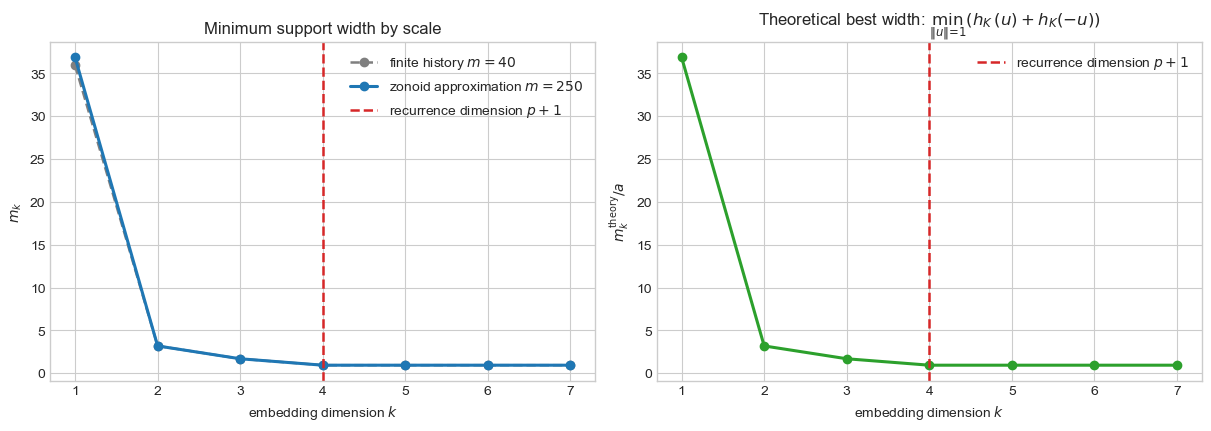

|<u_hat, u_AR>| at k=p+1: 1.000000
Width in AR direction: 0.941594
Closed-form AR-direction width: 0.941594


In [7]:
# READING GUIDE
# Extract table columns as NumPy arrays and visualize the width profile.
# The left panel compares truncation histories; agreement indicates that history is long enough.
# The right panel divides by the innovation half-width so coefficient geometry is easier to compare.
# The red vertical line marks the theoretical recurrence dimension p+1.
# The final printout checks the optimized direction against the known AR direction at that scale.

ks = result_table["k"].to_numpy()
finite_width = result_table["finite_width"].to_numpy()
theoretical_width = result_table["theoretical_width"].to_numpy()
theoretical_relative = result_table["theoretical_width_over_a"].to_numpy()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), constrained_layout=True)

axes[0].plot(ks, finite_width, "o--", lw=1.8, color="tab:gray", label=fr"finite history $m={history}$")
axes[0].plot(ks, theoretical_width, "o-", lw=2.2, color="tab:blue", label=fr"zonoid approximation $m={zonoid_history}$")
axes[0].axvline(p + 1, color="tab:red", ls="--", lw=1.8, label=r"recurrence dimension $p+1$")
axes[0].set(xticks=ks, xlabel=r"embedding dimension $k$", ylabel=r"$m_k$")
axes[0].set_title(r"Minimum support width by scale")
axes[0].legend()

axes[1].plot(ks, theoretical_relative, "o-", lw=2.2, color="tab:green")
axes[1].axvline(p + 1, color="tab:red", ls="--", lw=1.8, label=r"recurrence dimension $p+1$")
axes[1].set(xticks=ks, xlabel=r"embedding dimension $k$", ylabel=r"$m_k^{\mathrm{theory}}/a$")
axes[1].set_title(r"Theoretical best width: $\min_{\|u\|=1}(h_K(u)+h_K(-u))$")
axes[1].legend()

plt.show()

if p + 1 <= k_max:
    target_row = result_table.loc[result_table["k"] == p + 1].iloc[0]
    print(f"|<u_hat, u_AR>| at k=p+1: {target_row['alignment_with_AR_direction']:.6f}")
    print(f"Width in AR direction: {target_row['width_in_AR_direction']:.6f}")
    print(f"Closed-form AR-direction width: {target_row['closed_form_AR_width']:.6f}")


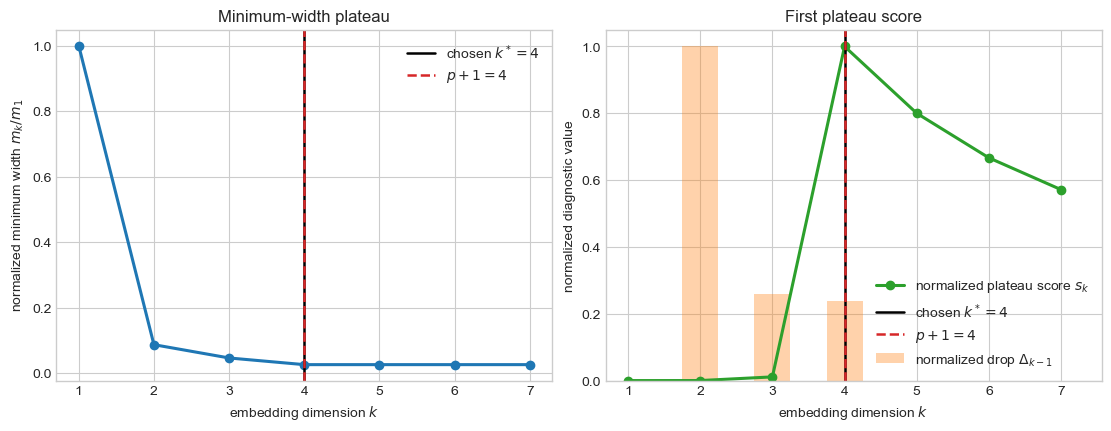

First plateau choice: k* = 4
Estimated AR order: p_hat = k* - 1 = 3


In [8]:
# READING GUIDE
# Turn a decreasing width curve into a first-plateau scale estimate.
# Log differences measure proportional improvements between adjacent dimensions.
# Future improvement accumulates all drops that would still occur after choosing a scale.
# A soft exponential score rewards negligible future improvement, while division by k favors the first plateau.
# The selected embedding dimension k* implies the order estimate p_hat=k*-1.

# FUNCTION: first_plateau_statistics
# Score each scale by how little proportional width improvement remains after it.
# Return adjacent drops, future drops, soft scores, and the first winning scale.
def first_plateau_statistics(width_sequence, temperature_fraction=0.05):
    widths = np.asarray(width_sequence, dtype=float)
    k_count = len(widths)
    # Use log widths so adjacent changes measure relative rather than absolute improvement.
    log_width = np.log(np.maximum(widths, np.finfo(float).tiny))
    # Keep only decreases; an increase is not evidence of geometric improvement.
    drops = np.maximum(0.0, log_width[:-1] - log_width[1:])
    drop_scale = max(float(np.max(drops)), 1e-12)

    future_improvement = np.zeros(k_count)
    for index in range(k_count - 1):
        future_improvement[index] = np.sum(drops[index:])

    temperature = temperature_fraction * drop_scale
    score = np.exp(-future_improvement / temperature) / np.arange(1, k_count + 1)
    selected_k = int(np.argmax(score) + 1)
    return {
        "drops": drops,
        "future_improvement": future_improvement,
        "score": score,
        "selected_k": selected_k,
    }


plateau_stats = first_plateau_statistics(theoretical_width)
selected_k = plateau_stats["selected_k"]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), constrained_layout=True)

axes[0].plot(ks, theoretical_width / theoretical_width[0], "o-", lw=2.2, color="tab:blue")
axes[0].axvline(selected_k, color="black", lw=1.8, label=fr"chosen $k^*={selected_k}$")
axes[0].axvline(p + 1, color="tab:red", ls="--", lw=1.8, label=fr"$p+1={p+1}$")
axes[0].set(
    xticks=ks,
    xlabel=r"embedding dimension $k$",
    ylabel=r"normalized minimum width $m_k/m_1$",
    title=r"Minimum-width plateau",
)
axes[0].legend()

score = plateau_stats["score"] / np.max(plateau_stats["score"])
drop_positions = ks[1:]
drops = plateau_stats["drops"]
normalized_drops = drops / max(np.max(drops), np.finfo(float).eps)
axes[1].bar(drop_positions, normalized_drops, width=0.5, color="tab:orange", alpha=0.35, label=r"normalized drop $\Delta_{k-1}$")
axes[1].plot(ks, score, "o-", lw=2.2, color="tab:green", label=r"normalized plateau score $s_k$")
axes[1].axvline(selected_k, color="black", lw=1.8, label=fr"chosen $k^*={selected_k}$")
axes[1].axvline(p + 1, color="tab:red", ls="--", lw=1.8, label=fr"$p+1={p+1}$")
axes[1].set(
    xticks=ks,
    xlabel=r"embedding dimension $k$",
    ylabel=r"normalized diagnostic value",
    title=r"First plateau score",
)
axes[1].legend()
plt.show()

print(f"First plateau choice: k* = {selected_k}")
print(f"Estimated AR order: p_hat = k* - 1 = {selected_k - 1}")


In [ ]:
# READING GUIDE
# Define the empirical counterpart of the population-width calculation.
# The uniform-AR simulator above supplies paths that are converted here into lag-window point clouds.
# Then build a rich bank of coordinate, PCA, and random unit directions.
# A practical directional epsilon-kernel keeps only points that are extreme in sampled directions.
# Minimum empirical width is estimated by projecting the coreset onto all candidate directions at once.

# FUNCTION: delay_cloud
# Convert one series into rows (X_t,X_(t-1),...,X_(t-k+1)).
def delay_cloud(series, embedding_dimension):
    x = np.asarray(series, dtype=float)
    k = int(embedding_dimension)
    if k < 1 or len(x) < k:
        raise ValueError("Require embedding_dimension >= 1 and len(series) >= embedding_dimension.")
    # Align current and past observations into equal-length lag-window columns.
    return np.column_stack([x[k - 1 - j:len(x) - j] for j in range(k)])


# FUNCTION: random_unit_directions
# Sample approximately uniform sphere directions by normalizing Gaussian vectors.
def random_unit_directions(dimension, count, rng=None):
    rng = np.random.default_rng(rng)
    if dimension == 1:
        return np.ones((1, 1))
    # Gaussian directions are rotationally symmetric before normalization.
    draws = rng.normal(size=(int(count), int(dimension)))
    norms = np.linalg.norm(draws, axis=1, keepdims=True)
    return draws / np.maximum(norms, np.finfo(float).eps)


# FUNCTION: coordinate_directions
# Return the positive and negative coordinate axes as guaranteed baseline directions.
def coordinate_directions(dimension):
    eye = np.eye(int(dimension))
    return np.vstack([eye, -eye])


# FUNCTION: pca_directions
# Use right singular vectors of the centered cloud as data-adaptive candidate directions.
def pca_directions(points, tol=1e-12):
    centered = np.asarray(points, dtype=float) - np.mean(points, axis=0, keepdims=True)
    if centered.shape[0] <= 1:
        return coordinate_directions(centered.shape[1])
    # SVD returns principal axes in the rows of V transpose.
    _, singular_values, vt = np.linalg.svd(centered, full_matrices=False)
    directions = vt[singular_values > tol]
    if len(directions) == 0:
        return coordinate_directions(centered.shape[1])
    return np.vstack([directions, -directions])


# FUNCTION: width_direction_bank
# Combine coordinate, PCA, and random directions into one search matrix.
def width_direction_bank(points, n_random=2048, rng=None):
    points = np.asarray(points, dtype=float)
    k = points.shape[1]
    directions = [coordinate_directions(k), pca_directions(points)]
    if k > 1 and n_random > 0:
        directions.append(random_unit_directions(k, n_random, rng=rng))
    return np.vstack(directions)


# FUNCTION: directional_epsilon_kernel
# Keep every point that is minimal or maximal in at least one sampled direction.
# The returned subset approximately preserves all directional widths.
def directional_epsilon_kernel(points, n_directions=512, rng=None):
    """Practical epsilon-kernel: keep extremes of P in a finite net of directions."""
    points = np.asarray(points, dtype=float)
    if points.ndim != 2:
        raise ValueError("points must be a two-dimensional array")
    k = points.shape[1]
    directions = width_direction_bank(points, n_random=n_directions, rng=rng)
    # One matrix multiplication projects every point onto every candidate direction.
    projections = points @ directions.T
    # Collect both support points for each sampled direction and remove duplicates.
    extreme_indices = np.unique(np.r_[np.argmin(projections, axis=0), np.argmax(projections, axis=0)])
    return points[extreme_indices], extreme_indices


# FUNCTION: empirical_width
# Project a point cloud onto one direction and return max projection minus min projection.
def empirical_width(points, direction):
    projections = np.asarray(points) @ np.asarray(direction)
    return float(np.max(projections) - np.min(projections))


# FUNCTION: estimate_empirical_minimum_width_by_directions
# Estimate minimum cloud width by evaluating many directions in one matrix multiplication.
# Optional known directions can be appended to the random/data-driven bank.
def estimate_empirical_minimum_width_by_directions(
    points, n_directions=4096, rng=None, candidate_directions=None,
):
    points = np.asarray(points, dtype=float)
    k = points.shape[1]
    if k == 1:
        return {
            "m_hat": empirical_width(points, np.ones(1)),
            "u_hat": np.ones(1),
            "source": "exact_1d",
        }

    direction_bank = width_direction_bank(points, n_random=n_directions, rng=rng)
    directions = [direction_bank]
    candidate_start = len(direction_bank)
    if candidate_directions is not None:
        candidates = np.asarray(candidate_directions, dtype=float)
        if candidates.ndim == 1:
            candidates = candidates.reshape(1, -1)
        candidate_norms = np.linalg.norm(candidates, axis=1, keepdims=True)
        candidates = candidates[candidate_norms[:, 0] > 0]
        if len(candidates):
            candidates = candidates / np.linalg.norm(candidates, axis=1, keepdims=True)
            directions.append(candidates)
    directions = np.vstack(directions)

    # One matrix multiplication projects every point onto every candidate direction.
    projections = points @ directions.T
    # Each column's range is the cloud width in one direction.
    widths = np.max(projections, axis=0) - np.min(projections, axis=0)
    # Select the direction with the smallest empirical projection range.
    best = int(np.argmin(widths))
    source = "candidate" if best >= candidate_start else "direction_bank"
    return {
        "m_hat": float(widths[best]),
        "u_hat": directions[best],
        "source": source,
    }


# FUNCTION: epsilon_kernel_width_curve
# Estimate one empirical minimum width for every embedding dimension 1,...,k_max.
# Also record how strongly the epsilon-kernel compresses each lag cloud.
def epsilon_kernel_width_curve(
    series, k_max, kernel_directions=512, width_directions=4096, rng=None,
):
    rng = np.random.default_rng(rng)
    rows = []
    for k in range(1, int(k_max) + 1):
        cloud = delay_cloud(series, k)
        coreset, coreset_indices = directional_epsilon_kernel(
            cloud, n_directions=kernel_directions, rng=rng
        )
        fit = estimate_empirical_minimum_width_by_directions(
            coreset, n_directions=width_directions, rng=rng
        )
        rows.append({
            "k": k,
            "empirical_min_width": fit["m_hat"],
            "coreset_size": len(coreset_indices),
            "cloud_size": len(cloud),
            "compression": len(coreset_indices) / len(cloud),
        })
    return pd.DataFrame(rows)


In [ ]:
# READING GUIDE
# Run a Monte Carlo experiment for the epsilon-kernel empirical estimator.
# Each replication simulates a fresh series for AR orders 1, 2, and 3.
# The first-plateau rule is applied to every estimated width curve.
# A summary table reports how frequently the chosen scale equals the target p+1.
# Plots show representative curves, selected scales, and coreset compression.

epsilon_experiment_settings = {
    "orders": [1, 2, 3],  # AR orders included in this experiment.
    "replications": 20,  # Independent simulated series per order.
    "sample_size": 4000,  # Observations retained after burn-in.
    "burnin": 800,  # Initial observations discarded to approach stationarity.
    "extra_scales": 4,  # Candidate dimensions examined beyond p.
    "kernel_directions": 768,  # Directions used to choose extreme coreset points.
    "width_directions": 4096,  # Directions searched when estimating minimum width.
    "seed": 20260721,  # Base seed making the experiment reproducible.
}

experiment_rng = np.random.default_rng(epsilon_experiment_settings["seed"])
epsilon_rows = []
example_curves = {}

for order in epsilon_experiment_settings["orders"]:
    phi_order = automatic_stationary_ar_coefficients(order)
    k_max_order = order + epsilon_experiment_settings["extra_scales"]
    for replication in range(epsilon_experiment_settings["replications"]):
        series = simulate_uniform_ar(
            phi_order,
            sample_size=epsilon_experiment_settings["sample_size"],
            burnin=epsilon_experiment_settings["burnin"],
            half_width=innovation_half_width,
            rng=experiment_rng,
        )
        curve = epsilon_kernel_width_curve(
            series,
            k_max=k_max_order,
            kernel_directions=epsilon_experiment_settings["kernel_directions"],
            width_directions=epsilon_experiment_settings["width_directions"],
            rng=experiment_rng,
        )
        stats = first_plateau_statistics(curve["empirical_min_width"].to_numpy())
        chosen_k = stats["selected_k"]
        epsilon_rows.append({
            "p": order,
            "target_k": order + 1,
            "replication": replication,
            "chosen_k": chosen_k,
            "correct": chosen_k == order + 1,
            "mean_coreset_size": curve["coreset_size"].mean(),
            "mean_compression": curve["compression"].mean(),
        })
        if replication == 0:
            example_curves[order] = curve.assign(
                score=stats["score"],
                selected_k=chosen_k,
                target_k=order + 1,
            )

epsilon_results = pd.DataFrame(epsilon_rows)
summary = (
    epsilon_results
    .groupby("p")
    .agg(
        target_k=("target_k", "first"),
        correct=("correct", "sum"),
        replications=("correct", "size"),
        mean_coreset_size=("mean_coreset_size", "mean"),
        mean_compression=("mean_compression", "mean"),
    )
)
summary["success_rate"] = summary["correct"] / summary["replications"]
print(summary.round(4).to_string())

fig, axes = plt.subplots(2, 3, figsize=(13, 7.2), constrained_layout=True)

for col, order in enumerate(epsilon_experiment_settings["orders"]):
    chosen = epsilon_results.loc[epsilon_results["p"] == order, "chosen_k"]
    k_max_order = order + epsilon_experiment_settings["extra_scales"]
    bins = np.arange(0.5, k_max_order + 1.5, 1)
    axes[0, col].hist(chosen, bins=bins, color="tab:blue", alpha=0.78, edgecolor="white")
    axes[0, col].axvline(order + 1, color="tab:red", ls="--", lw=2, label=fr"target $p+1={order + 1}$")
    axes[0, col].set(
        xticks=np.arange(1, k_max_order + 1),
        xlabel=r"chosen scale $k^*$",
        ylabel="count",
        title=fr"AR({order}) selections",
    )
    axes[0, col].legend()

    curve = example_curves[order]
    axes[1, col].plot(
        curve["k"], curve["empirical_min_width"] / curve["empirical_min_width"].iloc[0],
        "o-", lw=2, color="tab:green",
    )
    axes[1, col].axvline(curve["selected_k"].iloc[0], color="black", lw=1.8, label=fr"chosen $k^*={curve['selected_k'].iloc[0]}$")
    axes[1, col].axvline(order + 1, color="tab:red", ls="--", lw=2, label=fr"$p+1={order + 1}$")
    axes[1, col].set(
        xticks=curve["k"],
        xlabel=r"embedding dimension $k$",
        ylabel=r"normalized width",
        title=fr"Example curve, AR({order})",
    )
    axes[1, col].legend()

plt.show()


In [ ]:
# READING GUIDE
# Separate two reasons why an empirical minimum can differ from the population minimum.
# Filling error asks whether the finite cloud reaches the support boundary in the correct population direction.
# Spurious thinness asks whether searching many directions finds an artificially narrow finite-sample direction.
# The diagnostic compares population, full-cloud-at-oracle-direction, and optimized-coreset widths.
# This identifies whether failures come from sampling the support or from the directional optimizer.

# FUNCTION: population_width_curve_and_directions
# Compute population zonoid minima and minimizing directions for all candidate dimensions.
def population_width_curve_and_directions(
    phi, k_max, history=250, half_width=1.0, seed=0,
    de_maxiter=80, de_popsize=8,
):
    rows = []
    for k in range(1, int(k_max) + 1):
        generators = ar_window_zonoid_generators(phi, k, history, half_width)
        fit = estimate_minimum_zonotope_width(
            generators,
            seed=seed + k,
            de_maxiter=de_maxiter,
            de_popsize=de_popsize,
            candidate_directions=ar_recurrence_directions(phi, k),
        )
        rows.append({
            "k": k,
            "population_width": fit["m_hat"],
            "population_direction": fit["u_hat"],
            "population_source": fit["source"],
        })
    return pd.DataFrame(rows)


# FUNCTION: optimizer_vs_filling_diagnostic
# Decompose empirical error into support-filling error and optimizer-induced thinness.
# Return one diagnostic row per embedding dimension for a chosen AR order.
def optimizer_vs_filling_diagnostic(
    order,
    sample_size=40000,
    burnin=1000,
    extra_scales=4,
    zonoid_history=250,
    kernel_directions=768,
    width_directions=4096,
    seed=0,
):
    rng = np.random.default_rng(seed)
    phi_order = automatic_stationary_ar_coefficients(order)
    k_max_order = order + extra_scales
    series = simulate_uniform_ar(
        phi_order,
        sample_size=sample_size,
        burnin=burnin,
        half_width=innovation_half_width,
        rng=rng,
    )
    population = population_width_curve_and_directions(
        phi_order,
        k_max=k_max_order,
        history=zonoid_history,
        half_width=innovation_half_width,
        seed=seed + 10_000,
        de_maxiter=de_maxiter,
        de_popsize=de_popsize,
    )

    rows = []
    for _, population_row in population.iterrows():
        k = int(population_row["k"])
        cloud = delay_cloud(series, k)
        coreset, coreset_indices = directional_epsilon_kernel(
            cloud, n_directions=kernel_directions, rng=rng
        )
        u_star = np.asarray(population_row["population_direction"])
        # Measure finite-sample filling error without directional optimization error.
        empirical_oracle_width = empirical_width(cloud, u_star)
        # Measure how much the coreset changes width in that same oracle direction.
        empirical_coreset_oracle_width = empirical_width(coreset, u_star)
        empirical_fit = estimate_empirical_minimum_width_by_directions(
            coreset,
            n_directions=width_directions,
            rng=rng,
            candidate_directions=[u_star],
        )
        # Use the long-history zonoid minimum as the population reference value.
        population_width = float(population_row["population_width"])
        rows.append({
            "p": order,
            "k": k,
            "target_k": order + 1,
            "population_width": population_width,
            "empirical_width_at_u_star": empirical_oracle_width,
            "coreset_width_at_u_star": empirical_coreset_oracle_width,
            "empirical_min_width_alg": empirical_fit["m_hat"],
            "filling_error_at_u_star": empirical_oracle_width - population_width,
            "coreset_error_at_u_star": empirical_coreset_oracle_width - empirical_oracle_width,
            "spurious_thinness": empirical_oracle_width - empirical_fit["m_hat"],
            "relative_filling_error": (empirical_oracle_width - population_width) / population_width,
            "relative_spurious_thinness": (empirical_oracle_width - empirical_fit["m_hat"]) / max(empirical_oracle_width, np.finfo(float).eps),
            "coreset_size": len(coreset_indices),
            "cloud_size": len(cloud),
        })
    # Convert per-scale records into a table for selection and plotting.
    diagnostic = pd.DataFrame(rows)
    diagnostic["selected_k_alg"] = first_plateau_statistics(
        diagnostic["empirical_min_width_alg"].to_numpy()
    )["selected_k"]
    diagnostic["selected_k_oracle_empirical"] = first_plateau_statistics(
        diagnostic["empirical_width_at_u_star"].to_numpy()
    )["selected_k"]
    diagnostic["selected_k_population"] = first_plateau_statistics(
        diagnostic["population_width"].to_numpy()
    )["selected_k"]
    return diagnostic


diagnostic_settings = {
    "orders": [1, 2, 3],  # AR orders included in this experiment.
    "sample_size": 40000,  # Observations retained after burn-in.
    "burnin": 1000,  # Initial observations discarded to approach stationarity.
    "extra_scales": 4,  # Candidate dimensions examined beyond p.
    "zonoid_history": 250,  # Number of impulse-response lags in the population approximation.
    "kernel_directions": 768,  # Directions used to choose extreme coreset points.
    "width_directions": 4096,  # Directions searched when estimating minimum width.
    "seed": 20260723,  # Base seed making the experiment reproducible.
}

diagnostics = []
for order in diagnostic_settings["orders"]:
    diagnostic = optimizer_vs_filling_diagnostic(
        order,
        sample_size=diagnostic_settings["sample_size"],
        burnin=diagnostic_settings["burnin"],
        extra_scales=diagnostic_settings["extra_scales"],
        zonoid_history=diagnostic_settings["zonoid_history"],
        kernel_directions=diagnostic_settings["kernel_directions"],
        width_directions=diagnostic_settings["width_directions"],
        seed=diagnostic_settings["seed"] + 100 * order,
    )
    diagnostics.append(diagnostic)

diagnostic_table = pd.concat(diagnostics, ignore_index=True)

selected_summary = (
    diagnostic_table
    .groupby("p")[["target_k", "selected_k_population", "selected_k_oracle_empirical", "selected_k_alg"]]
    .first()
)
print(selected_summary.to_string())

for order in diagnostic_settings["orders"]:
    columns = [
        "k", "population_width", "empirical_width_at_u_star", "empirical_min_width_alg",
        "relative_filling_error", "relative_spurious_thinness", "coreset_size", "cloud_size",
    ]
    print("\nAR({})".format(order))
    print(diagnostic_table.loc[diagnostic_table["p"] == order, columns].round(4).to_string(index=False))

fig, axes = plt.subplots(3, 2, figsize=(12, 10.5), constrained_layout=True)

for row_index, order in enumerate(diagnostic_settings["orders"]):
    sub = diagnostic_table[diagnostic_table["p"] == order]
    k_values = sub["k"].to_numpy()

    axes[row_index, 0].plot(k_values, sub["population_width"], "o-", lw=2.2, label=r"population $m_k$")
    axes[row_index, 0].plot(k_values, sub["empirical_width_at_u_star"], "s-", lw=2.0, label=r"empirical at $u_k^*$")
    axes[row_index, 0].plot(k_values, sub["empirical_min_width_alg"], "^-", lw=2.0, label=r"empirical minimum")
    axes[row_index, 0].axvline(order + 1, color="tab:red", ls="--", lw=1.8, label=fr"target $p+1={order + 1}$")
    axes[row_index, 0].set(
        xticks=k_values,
        xlabel=r"embedding dimension $k$",
        ylabel=r"width",
        title=fr"AR({order}): width decomposition",
    )
    axes[row_index, 0].legend()

    axes[row_index, 1].bar(
        k_values - 0.18,
        sub["relative_filling_error"],
        width=0.36,
        color="tab:orange",
        alpha=0.78,
        label=r"filling error at $u_k^*$",
    )
    axes[row_index, 1].bar(
        k_values + 0.18,
        sub["relative_spurious_thinness"],
        width=0.36,
        color="tab:purple",
        alpha=0.72,
        label=r"spurious empirical thinness",
    )
    axes[row_index, 1].axhline(0.0, color="black", lw=1.0)
    axes[row_index, 1].axvline(order + 1, color="tab:red", ls="--", lw=1.8)
    axes[row_index, 1].set(
        xticks=k_values,
        xlabel=r"embedding dimension $k$",
        ylabel=r"relative error",
        title=fr"AR({order}): failure-mode diagnostic",
    )
    axes[row_index, 1].legend()

plt.show()


In [ ]:
# READING GUIDE
# Compare the known AR recurrence width with the empirical minimum-width estimator over repeated samples.
# The oracle value 2a/||q_phi|| is available once k>=p+1.
# Each replication produces a full curve, a plateau selection, and width/oracle ratios.
# The summary reports order-recovery success, while the panels show bias and variability by scale.

# FUNCTION: oracle_recurrence_width
# Evaluate the closed-form plateau width 2a/||q_phi||.
def oracle_recurrence_width(phi, half_width=1.0):
    return float(2.0 * half_width / np.linalg.norm(ar_recurrence_vector(phi)))


# FUNCTION: oracle_vs_empirical_min_width_experiment
# Repeat simulation and empirical width estimation, then compare every curve with the oracle plateau.
def oracle_vs_empirical_min_width_experiment(
    orders=(1, 2, 3),
    replications=10,
    sample_size=40000,
    burnin=1000,
    extra_scales=4,
    kernel_directions=768,
    width_directions=4096,
    seed=20260724,
):
    rng = np.random.default_rng(seed)
    rows = []
    example_curves = {}

    for order in orders:
        phi_order = automatic_stationary_ar_coefficients(order)
        oracle_width = oracle_recurrence_width(phi_order, innovation_half_width)
        k_max_order = order + extra_scales

        for replication in range(replications):
            series = simulate_uniform_ar(
                phi_order,
                sample_size=sample_size,
                burnin=burnin,
                half_width=innovation_half_width,
                rng=rng,
            )
            curve = epsilon_kernel_width_curve(
                series,
                k_max=k_max_order,
                kernel_directions=kernel_directions,
                width_directions=width_directions,
                rng=rng,
            )
            curve["p"] = order
            curve["replication"] = replication
            curve["target_k"] = order + 1
            curve["oracle_width"] = oracle_width
            curve["ratio_to_oracle"] = curve["empirical_min_width"] / oracle_width
            curve["absolute_oracle_gap"] = curve["empirical_min_width"] - oracle_width
            curve["relative_oracle_gap"] = curve["ratio_to_oracle"] - 1.0
            curve["selected_k"] = first_plateau_statistics(
                curve["empirical_min_width"].to_numpy()
            )["selected_k"]
            rows.append(curve)

            if replication == 0:
                example_curves[order] = curve.copy()

    return pd.concat(rows, ignore_index=True), example_curves


oracle_comparison_settings = {
    "orders": (1, 2, 3),  # AR orders included in this experiment.
    "replications": 10,  # Independent simulated series per order.
    "sample_size": 40000,  # Observations retained after burn-in.
    "burnin": 1000,  # Initial observations discarded to approach stationarity.
    "extra_scales": 4,  # Candidate dimensions examined beyond p.
    "kernel_directions": 768,  # Directions used to choose extreme coreset points.
    "width_directions": 4096,  # Directions searched when estimating minimum width.
    "seed": 20260724,  # Base seed making the experiment reproducible.
}

oracle_comparison, oracle_example_curves = oracle_vs_empirical_min_width_experiment(
    **oracle_comparison_settings
)

oracle_summary = (
    oracle_comparison
    .groupby(["p", "k"])
    .agg(
        target_k=("target_k", "first"),
        oracle_width=("oracle_width", "first"),
        mean_empirical_width=("empirical_min_width", "mean"),
        sd_empirical_width=("empirical_min_width", "std"),
        mean_ratio_to_oracle=("ratio_to_oracle", "mean"),
        sd_ratio_to_oracle=("ratio_to_oracle", "std"),
        mean_coreset_size=("coreset_size", "mean"),
    )
    .reset_index()
)

selection_runs = oracle_comparison.drop_duplicates(["p", "replication"]).copy()
# Mark a replication successful exactly when k*=p+1.
selection_runs["correct"] = selection_runs["selected_k"] == selection_runs["target_k"]
selection_summary = (
    selection_runs
    .groupby("p")
    .agg(
        target_k=("target_k", "first"),
        correct=("correct", "sum"),
        replications=("correct", "size"),
    )
)
selection_summary["success_rate"] = selection_summary["correct"] / selection_summary["replications"]

print("Selection summary")
print(selection_summary.to_string())
print("\nMean empirical minimum width divided by oracle width")
print(
    oracle_summary[["p", "k", "target_k", "mean_ratio_to_oracle", "sd_ratio_to_oracle", "mean_coreset_size"]]
    .round(4)
    .to_string(index=False)
)

fig, axes = plt.subplots(2, 3, figsize=(13, 7.3), constrained_layout=True)

for column, order in enumerate(oracle_comparison_settings["orders"]):
    sub = oracle_comparison[oracle_comparison["p"] == order]
    summary_sub = oracle_summary[oracle_summary["p"] == order]
    example = oracle_example_curves[order]
    k_values = summary_sub["k"].to_numpy()

    axes[0, column].plot(
        example["k"],
        example["empirical_min_width"],
        "o-",
        lw=2.2,
        color="tab:blue",
        label=r"example $\widehat m_k$",
    )
    axes[0, column].axhline(
        example["oracle_width"].iloc[0],
        color="black",
        ls="--",
        lw=1.9,
        label=r"oracle plateau",
    )
    axes[0, column].axvline(
        order + 1,
        color="tab:red",
        ls=":",
        lw=2.0,
        label=fr"$p+1={order + 1}$",
    )
    axes[0, column].set(
        xticks=example["k"],
        xlabel=r"embedding dimension $k$",
        ylabel=r"width",
        title=fr"AR({order}): one empirical curve",
    )
    axes[0, column].legend()

    axes[1, column].errorbar(
        k_values,
        summary_sub["mean_ratio_to_oracle"],
        yerr=summary_sub["sd_ratio_to_oracle"],
        fmt="o-",
        lw=2.2,
        capsize=4,
        color="tab:green",
        label=r"mean $\widehat m_k/m_{\mathrm{oracle}}$",
    )
    axes[1, column].axhline(1.0, color="black", ls="--", lw=1.8)
    axes[1, column].axvline(order + 1, color="tab:red", ls=":", lw=2.0)
    axes[1, column].set(
        xticks=k_values,
        xlabel=r"embedding dimension $k$",
        ylabel=r"ratio to oracle",
        title=fr"AR({order}): empirical/oracle ratio",
    )
    axes[1, column].legend()

plt.show()


In [ ]:
# READING GUIDE
# Explore two spectral summaries of an empirical minimum-width curve.
# A scale-similarity matrix compares every pair of widths and its Perron vector ranks the scales.
# A separate birth-death construction turns adjacent width changes into a stationary distribution.
# These are experimental alternatives to the direct first-plateau rule.

# FUNCTION: min_width_scale_matrix
# Convert positive widths into a symmetric pairwise scale-similarity matrix.
def min_width_scale_matrix(widths):
    widths = np.asarray(widths, dtype=float)
    n = len(widths)
    matrix = np.empty((n, n))
    for i in range(n):
        for j in range(n):
            matrix[i, j] = widths[i] + widths[j] - widths[max(i, j)]
    matrix = np.maximum(matrix, 0.0)
    return matrix


# FUNCTION: perron_vector
# Extract and normalize the dominant nonnegative eigenvector of a scale matrix.
def perron_vector(matrix):
    matrix = np.asarray(matrix, dtype=float)
    values, vectors = np.linalg.eigh((matrix + matrix.T) / 2.0)
    vector = np.abs(vectors[:, np.argmax(values)])
    total = np.sum(vector)
    if total <= 0:
        return np.ones(len(vector)) / len(vector)
    return vector / total


# FUNCTION: birth_death_stationary_from_widths
# Build a nearest-neighbor birth-death chain from adjacent proportional width changes.
def birth_death_stationary_from_widths(widths, eta_fraction=0.15, epsilon=1e-12):
    widths = np.asarray(widths, dtype=float)
    log_widths = np.log(np.maximum(widths, np.finfo(float).tiny))
    drops = np.maximum(0.0, log_widths[:-1] - log_widths[1:])
    eta = eta_fraction * max(float(np.max(drops)), epsilon)

    log_pi = np.zeros(len(widths))
    for k in range(1, len(widths)):
        log_pi[k] = log_pi[k - 1] + np.log(drops[k - 1] + epsilon) - np.log(eta)

    log_pi -= np.max(log_pi)
    pi = np.exp(log_pi)
    pi /= np.sum(pi)
    return pi, drops, eta


# FUNCTION: perron_and_birth_death_for_curve
# Apply both experimental spectral summaries to the same width curve.
def perron_and_birth_death_for_curve(widths):
    matrix = min_width_scale_matrix(widths)
    perron = perron_vector(matrix)
    stationary, drops, eta = birth_death_stationary_from_widths(widths)
    return matrix, perron, stationary, drops, eta


# Uses the first empirical curve for each p from the oracle-comparison experiment above.
fig, axes = plt.subplots(2, 3, figsize=(13, 7.2), constrained_layout=True)
perron_bd_rows = []

for column, order in enumerate(oracle_comparison_settings["orders"]):
    curve = oracle_example_curves[order]
    widths = curve["empirical_min_width"].to_numpy()
    k_values = curve["k"].to_numpy()
    matrix, perron, stationary, drops, eta = perron_and_birth_death_for_curve(widths)

    perron_choice = int(k_values[np.argmax(perron)])
    stationary_choice = int(k_values[np.argmax(stationary)])
    perron_bd_rows.append({
        "p": order,
        "target_k": order + 1,
        "perron_choice": perron_choice,
        "stationary_choice": stationary_choice,
        "eta": eta,
    })

    axes[0, column].plot(k_values, widths / widths[0], "o-", lw=2.0, color="tab:blue", label=r"normalized $\widehat m_k$")
    axes[0, column].plot(k_values, perron / np.max(perron), "s-", lw=2.0, color="tab:purple", label="Perron vector")
    axes[0, column].axvline(order + 1, color="tab:red", ls="--", lw=1.8, label=fr"target $p+1={order + 1}$")
    axes[0, column].axvline(perron_choice, color="black", lw=1.4, alpha=0.7, label=fr"Perron peak {perron_choice}")
    axes[0, column].set(
        xticks=k_values,
        xlabel=r"embedding dimension $k$",
        ylabel="normalized value",
        title=fr"AR({order}): Perron vector",
    )
    axes[0, column].legend()

    axes[1, column].plot(k_values, widths / widths[0], "o-", lw=2.0, color="tab:blue", label=r"normalized $\widehat m_k$")
    axes[1, column].plot(k_values, stationary / np.max(stationary), "s-", lw=2.0, color="tab:green", label="stationary distribution")
    axes[1, column].axvline(order + 1, color="tab:red", ls="--", lw=1.8, label=fr"target $p+1={order + 1}$")
    axes[1, column].axvline(stationary_choice, color="black", lw=1.4, alpha=0.7, label=fr"stationary peak {stationary_choice}")
    axes[1, column].set(
        xticks=k_values,
        xlabel=r"embedding dimension $k$",
        ylabel="normalized value",
        title=fr"AR({order}): birth-death distribution",
    )
    axes[1, column].legend()

perron_bd_summary = pd.DataFrame(perron_bd_rows)
print(perron_bd_summary.to_string(index=False))
plt.show()


In [ ]:
# READING GUIDE
# Implement the stationary-distribution formulas used in the thesis more literally.
# A Doob transform converts a nonnegative matrix and its Perron eigenvector into a Markov chain.
# A strictly increasing cumulative gain profile is derived from width drops.
# The resulting Perron-Doob and birth-death distributions are compared scale by scale.

# FUNCTION: perron_doob_stationary
# Use the Perron eigenpair to turn a nonnegative matrix into a Markov transition matrix.
def perron_doob_stationary(matrix):
    matrix = np.asarray(matrix, dtype=float)
    sym_matrix = (matrix + matrix.T) / 2.0
    values, vectors = np.linalg.eigh(sym_matrix)
    vector = np.abs(vectors[:, np.argmax(values)])
    if np.sum(vector) <= 0:
        vector = np.ones(len(vector))
    vector = vector / np.linalg.norm(vector)
    stationary = vector ** 2
    stationary = stationary / np.sum(stationary)
    return vector, stationary


# FUNCTION: strictly_increasing_width_gain
# Accumulate positive log-width drops into a strictly increasing scale coordinate.
def strictly_increasing_width_gain(widths, epsilon=1e-10):
    widths = np.asarray(widths, dtype=float)
    log_widths = np.log(np.maximum(widths, np.finfo(float).tiny))
    raw_gain = log_widths[0] - log_widths
    monotone_gain = np.maximum.accumulate(raw_gain)
    return monotone_gain + epsilon * np.arange(1, len(widths) + 1)


# FUNCTION: thesis_birth_death_stationary
# Compute the thesis birth-death transition matrix and its stationary distribution.
def thesis_birth_death_stationary(c_values):
    c_values = np.asarray(c_values, dtype=float)
    increments = np.diff(c_values)
    if np.any(increments <= 0):
        raise ValueError("c_values must be strictly increasing.")

    n = len(c_values)
    rates = np.empty(n)
    rates[0] = 1.0 / increments[0]
    rates[-1] = 1.0 / increments[-1]
    if n > 2:
        rates[1:-1] = 1.0 / increments[:-1] + 1.0 / increments[1:]
    stationary = rates / np.sum(rates)
    return stationary, rates, increments


# FUNCTION: thesis_stationary_distributions_from_widths
# Produce the thesis Perron-Doob and birth-death distributions from one width sequence.
def thesis_stationary_distributions_from_widths(widths):
    matrix = min_width_scale_matrix(widths)
    perron, doob_stationary = perron_doob_stationary(matrix)
    c_values = strictly_increasing_width_gain(widths)
    bd_stationary, bd_rates, bd_increments = thesis_birth_death_stationary(c_values)
    return {
        "matrix": matrix,
        "perron": perron,
        "doob_stationary": doob_stationary,
        "c_values": c_values,
        "bd_stationary": bd_stationary,
        "bd_rates": bd_rates,
        "bd_increments": bd_increments,
    }


# Uses the first empirical curve for each p from the oracle-comparison experiment above.
fig, axes = plt.subplots(3, 3, figsize=(14, 10.5), constrained_layout=True)
thesis_stationary_rows = []

for row, order in enumerate(oracle_comparison_settings["orders"]):
    curve = oracle_example_curves[order]
    widths = curve["empirical_min_width"].to_numpy()
    k_values = curve["k"].to_numpy()
    result = thesis_stationary_distributions_from_widths(widths)

    doob_choice = int(k_values[np.argmax(result["doob_stationary"])])
    bd_choice = int(k_values[np.argmin(result["bd_stationary"])])
    thesis_stationary_rows.append({
        "p": order,
        "target_k": order + 1,
        "doob_stationary_peak": doob_choice,
        "bd_stationary_minimum": bd_choice,
    })

    axes[row, 0].plot(k_values, widths / widths[0], "o-", lw=2.0, color="tab:blue", label=r"normalized $\widehat m_k$")
    axes[row, 0].axvline(order + 1, color="tab:red", ls="--", lw=1.8, label=fr"target $p+1={order + 1}$")
    axes[row, 0].set(
        xticks=k_values,
        xlabel=r"embedding dimension $k$",
        ylabel=r"normalized width",
        title=fr"AR({order}): empirical width curve",
    )
    axes[row, 0].legend()

    axes[row, 1].plot(k_values, result["perron"] / np.max(result["perron"]), "o-", lw=2.0, color="tab:purple", label="Perron vector")
    axes[row, 1].plot(k_values, result["doob_stationary"] / np.max(result["doob_stationary"]), "s-", lw=2.0, color="tab:green", label=r"Doob stationary $\pi$")
    axes[row, 1].axvline(order + 1, color="tab:red", ls="--", lw=1.8)
    axes[row, 1].axvline(doob_choice, color="black", lw=1.5, alpha=0.75, label=fr"Doob peak {doob_choice}")
    axes[row, 1].set(
        xticks=k_values,
        xlabel=r"embedding dimension $k$",
        ylabel="normalized value",
        title=fr"AR({order}): Perron-Doob stationary distribution",
    )
    axes[row, 1].legend()

    axes[row, 2].plot(k_values, result["c_values"], "o-", lw=2.0, color="tab:blue", label=r"width gain $c_k$")
    axes[row, 2].plot(k_values, result["bd_stationary"] / np.max(result["bd_stationary"]), "s-", lw=2.0, color="tab:orange", label=r"BD stationary $\pi^{BD}$")
    axes[row, 2].axvline(order + 1, color="tab:red", ls="--", lw=1.8)
    axes[row, 2].axvline(bd_choice, color="black", lw=1.5, alpha=0.75, label=fr"BD min {bd_choice}")
    axes[row, 2].set(
        xticks=k_values,
        xlabel=r"embedding dimension $k$",
        ylabel="normalized / gain value",
        title=fr"AR({order}): thesis birth-death distribution",
    )
    axes[row, 2].legend()

thesis_stationary_summary = pd.DataFrame(thesis_stationary_rows)
print(thesis_stationary_summary.to_string(index=False))
plt.show()


In [ ]:
# READING GUIDE
# Compare minimum widths computed from three levels of information.
# The oracle curve uses the theoretical support zonoid.
# The full-cloud curve uses all simulated lag windows; the coreset curve uses only extreme points.
# All empirical variants use a shared direction bank so differences reflect point reduction, not random directions.
# The experiment measures both approximation accuracy and compression.

# FUNCTION: minimum_width_over_given_directions
# Find the narrowest projection of a cloud over a fixed shared direction matrix.
def minimum_width_over_given_directions(points, directions):
    points = np.asarray(points, dtype=float)
    directions = np.asarray(directions, dtype=float)
    # One matrix multiplication projects every point onto every candidate direction.
    projections = points @ directions.T
    # Each column's range is the cloud width in one direction.
    widths = np.max(projections, axis=0) - np.min(projections, axis=0)
    # Select the direction with the smallest empirical projection range.
    best = int(np.argmin(widths))
    return float(widths[best]), directions[best]


# FUNCTION: oracle_full_cloud_coreset_width_curve
# Compare population, full-cloud, and coreset minimum widths on the same dimensions.
def oracle_full_cloud_coreset_width_curve(
    order,
    sample_size=40000,
    burnin=1000,
    extra_scales=4,
    kernel_directions=768,
    width_directions=2048,
    seed=0,
):
    rng = np.random.default_rng(seed)
    phi_order = automatic_stationary_ar_coefficients(order)
    oracle_width = oracle_recurrence_width(phi_order, innovation_half_width)
    k_max_order = order + extra_scales
    series = simulate_uniform_ar(
        phi_order,
        sample_size=sample_size,
        burnin=burnin,
        half_width=innovation_half_width,
        rng=rng,
    )

    rows = []
    for k in range(1, k_max_order + 1):
        cloud = delay_cloud(series, k)
        coreset, coreset_indices = directional_epsilon_kernel(
            cloud,
            n_directions=kernel_directions,
            rng=rng,
        )
        directions = width_direction_bank(cloud, n_random=width_directions, rng=rng)
        full_width, full_direction = minimum_width_over_given_directions(cloud, directions)
        coreset_width, coreset_direction = minimum_width_over_given_directions(coreset, directions)
        rows.append({
            "p": order,
            "k": k,
            "target_k": order + 1,
            "oracle_width": oracle_width,
            "min_width_P_k": full_width,
            "min_width_Q_k": coreset_width,
            "ratio_P_to_oracle": full_width / oracle_width,
            "ratio_Q_to_oracle": coreset_width / oracle_width,
            "coreset_size": len(coreset_indices),
            "cloud_size": len(cloud),
            "compression": len(coreset_indices) / len(cloud),
        })
    return pd.DataFrame(rows)


oracle_p_q_settings = {
    "orders": (1, 2, 3),  # AR orders included in this experiment.
    "sample_size": 40000,  # Observations retained after burn-in.
    "burnin": 1000,  # Initial observations discarded to approach stationarity.
    "extra_scales": 4,  # Candidate dimensions examined beyond p.
    "kernel_directions": 768,  # Directions used to choose extreme coreset points.
    "width_directions": 2048,  # Directions searched when estimating minimum width.
    "seed": 20260725,  # Base seed making the experiment reproducible.
}

oracle_p_q_curves = []
for order in oracle_p_q_settings["orders"]:
    oracle_p_q_curves.append(
        oracle_full_cloud_coreset_width_curve(
            order,
            sample_size=oracle_p_q_settings["sample_size"],
            burnin=oracle_p_q_settings["burnin"],
            extra_scales=oracle_p_q_settings["extra_scales"],
            kernel_directions=oracle_p_q_settings["kernel_directions"],
            width_directions=oracle_p_q_settings["width_directions"],
            seed=oracle_p_q_settings["seed"] + 100 * order,
        )
    )

oracle_p_q_table = pd.concat(oracle_p_q_curves, ignore_index=True)

for order in oracle_p_q_settings["orders"]:
    columns = [
        "k", "oracle_width", "min_width_P_k", "min_width_Q_k",
        "ratio_P_to_oracle", "ratio_Q_to_oracle", "coreset_size", "cloud_size",
    ]
    print("\nAR({})".format(order))
    print(oracle_p_q_table.loc[oracle_p_q_table["p"] == order, columns].round(4).to_string(index=False))

fig, axes = plt.subplots(2, 3, figsize=(13, 7.4), constrained_layout=True)

for column, order in enumerate(oracle_p_q_settings["orders"]):
    sub = oracle_p_q_table[oracle_p_q_table["p"] == order]
    k_values = sub["k"].to_numpy()

    axes[0, column].plot(k_values, sub["min_width_P_k"], "o-", lw=2.2, color="tab:blue", label=r"min over $P_k$")
    axes[0, column].plot(k_values, sub["min_width_Q_k"], "s-", lw=2.2, color="tab:green", label=r"min over $Q_k$")
    axes[0, column].axhline(sub["oracle_width"].iloc[0], color="black", ls="--", lw=1.9, label="oracle")
    axes[0, column].axvline(order + 1, color="tab:red", ls=":", lw=2.0, label=fr"$p+1={order + 1}$")
    axes[0, column].set(
        xticks=k_values,
        xlabel=r"embedding dimension $k$",
        ylabel=r"width",
        title=fr"AR({order}): width curves",
    )
    axes[0, column].legend()

    axes[1, column].plot(k_values, sub["ratio_P_to_oracle"], "o-", lw=2.2, color="tab:blue", label=r"$\widehat m(P_k)/m_{oracle}$")
    axes[1, column].plot(k_values, sub["ratio_Q_to_oracle"], "s-", lw=2.2, color="tab:green", label=r"$\widehat m(Q_k)/m_{oracle}$")
    axes[1, column].axhline(1.0, color="black", ls="--", lw=1.9)
    axes[1, column].axvline(order + 1, color="tab:red", ls=":", lw=2.0)
    axes[1, column].set(
        xticks=k_values,
        xlabel=r"embedding dimension $k$",
        ylabel="ratio to oracle",
        title=fr"AR({order}): ratio to oracle",
    )
    axes[1, column].legend()

plt.show()


In [ ]:
# READING GUIDE
# Construct a local kink score designed to detect the first large change followed by stabilization.
# The score combines the current log-width drop with a penalty for later drops.
# Pairwise score similarity produces a nonnegative matrix whose Perron vector gives a spectral selection.
# Monte Carlo results compare the selected dimension with the target p+1.

# FUNCTION: first_kink_score
# Score a scale highly when it has a large local drop but little improvement remains afterward.
def first_kink_score(widths, tau_fraction=0.25, epsilon=1e-12):
    widths = np.asarray(widths, dtype=float)
    log_widths = np.log(np.maximum(widths, np.finfo(float).tiny))
    raw_drops = np.maximum(0.0, log_widths[:-1] - log_widths[1:])
    tau = tau_fraction * max(float(np.max(raw_drops)), epsilon)

    score = np.zeros(len(widths))
    for index in range(1, len(widths) - 1):
        backward_drop = raw_drops[index - 1]
        forward_drop = raw_drops[index]
        score[index] = backward_drop * np.exp(-forward_drop / tau)
    return score, raw_drops, tau


# FUNCTION: kink_score_similarity_matrix
# Turn scalar kink scores into a positive pairwise similarity matrix.
def kink_score_similarity_matrix(score, rho=1.0, diagonal_epsilon=1e-12):
    score = np.asarray(score, dtype=float)
    n = len(score)
    scale_distance = np.subtract.outer(np.arange(n), np.arange(n))
    locality = np.exp(-(scale_distance ** 2) / (2.0 * rho ** 2))
    matrix = np.sqrt(np.outer(score, score)) * locality
    matrix += diagonal_epsilon * np.eye(n)
    return matrix


# FUNCTION: kink_spectral_selection
# Run kink scoring, construct its similarity matrix, and select by the Perron vector.
def kink_spectral_selection(widths, tau_fraction=0.25, rho=1.0):
    score, drops, tau = first_kink_score(widths, tau_fraction=tau_fraction)
    matrix = kink_score_similarity_matrix(score, rho=rho)
    vector = perron_vector(matrix)
    selected_k = int(np.argmax(vector) + 1)
    return {
        "score": score,
        "drops": drops,
        "tau": tau,
        "matrix": matrix,
        "perron": vector,
        "selected_k": selected_k,
    }


kink_spectral_settings = {
    "orders": (1, 2, 3),  # AR orders included in this experiment.
    "sample_size": 40000,  # Observations retained after burn-in.
    "burnin": 1000,  # Initial observations discarded to approach stationarity.
    "extra_scales": 4,  # Candidate dimensions examined beyond p.
    "kernel_directions": 768,  # Directions used to choose extreme coreset points.
    "width_directions": 2048,  # Directions searched when estimating minimum width.
    "tau_fraction": 0.25,  # Relative smoothing scale in the kink score.
    "rho": 1.0,  # Sensitivity of pairwise kink-score similarity.
    "seed": 20260726,  # Base seed making the experiment reproducible.
}

kink_curves = []
for order in kink_spectral_settings["orders"]:
    curve = oracle_full_cloud_coreset_width_curve(
        order,
        sample_size=kink_spectral_settings["sample_size"],
        burnin=kink_spectral_settings["burnin"],
        extra_scales=kink_spectral_settings["extra_scales"],
        kernel_directions=kink_spectral_settings["kernel_directions"],
        width_directions=kink_spectral_settings["width_directions"],
        seed=kink_spectral_settings["seed"] + 100 * order,
    )
    result = kink_spectral_selection(
        curve["min_width_Q_k"].to_numpy(),
        tau_fraction=kink_spectral_settings["tau_fraction"],
        rho=kink_spectral_settings["rho"],
    )
    curve["kink_score"] = result["score"]
    curve["kink_perron"] = result["perron"]
    curve["kink_selected_k"] = result["selected_k"]
    kink_curves.append(curve)

kink_spectral_table = pd.concat(kink_curves, ignore_index=True)
kink_spectral_summary = (
    kink_spectral_table
    .groupby("p")[["target_k", "kink_selected_k"]]
    .first()
)
kink_spectral_summary["correct"] = kink_spectral_summary["target_k"] == kink_spectral_summary["kink_selected_k"]
print(kink_spectral_summary.to_string())

fig, axes = plt.subplots(2, 3, figsize=(13, 7.4), constrained_layout=True)

for column, order in enumerate(kink_spectral_settings["orders"]):
    sub = kink_spectral_table[kink_spectral_table["p"] == order]
    k_values = sub["k"].to_numpy()
    selected_k = int(sub["kink_selected_k"].iloc[0])

    axes[0, column].plot(k_values, sub["min_width_Q_k"] / sub["min_width_Q_k"].iloc[0], "o-", lw=2.2, color="tab:blue", label=r"normalized $\widehat m_k(Q_k)$")
    axes[0, column].plot(k_values, sub["kink_score"] / max(sub["kink_score"].max(), np.finfo(float).eps), "s-", lw=2.2, color="tab:orange", label=r"kink score $g_k$")
    axes[0, column].axvline(order + 1, color="tab:red", ls="--", lw=1.9, label=fr"target $p+1={order + 1}$")
    axes[0, column].axvline(selected_k, color="black", lw=1.5, alpha=0.75, label=fr"selected {selected_k}")
    axes[0, column].set(
        xticks=k_values,
        xlabel=r"embedding dimension $k$",
        ylabel="normalized value",
        title=fr"AR({order}): kink score",
    )
    axes[0, column].legend()

    axes[1, column].plot(k_values, sub["kink_score"] / max(sub["kink_score"].max(), np.finfo(float).eps), "o-", lw=2.2, color="tab:orange", label=r"kink score $g_k$")
    axes[1, column].plot(k_values, sub["kink_perron"] / max(sub["kink_perron"].max(), np.finfo(float).eps), "s-", lw=2.2, color="tab:purple", label="Perron vector")
    axes[1, column].axvline(order + 1, color="tab:red", ls="--", lw=1.9)
    axes[1, column].axvline(selected_k, color="black", lw=1.5, alpha=0.75)
    axes[1, column].set(
        xticks=k_values,
        xlabel=r"embedding dimension $k$",
        ylabel="normalized value",
        title=fr"AR({order}): spectral kink selection",
    )
    axes[1, column].legend()

plt.show()


In [ ]:
# READING GUIDE
# Directly compare the theoretical AR recurrence direction with the coreset's optimized thinnest direction.
# The recurrence vector is zero-padded to the requested embedding dimension.
# For every k, evaluate the empirical width in that oracle direction and the minimum over the direction bank.
# Direction alignment and width gaps show whether the optimizer is finding the intended geometric signal.

# FUNCTION: embedded_recurrence_direction
# Place q_phi in the first p+1 coordinates of R^k and normalize it.
def embedded_recurrence_direction(phi, embedding_dimension):
    raw = ar_recurrence_vector(phi)
    k = int(embedding_dimension)
    if k < len(raw):
        return None
    direction = np.zeros(k)
    direction[:len(raw)] = raw
    return direction / np.linalg.norm(direction)


# FUNCTION: oracle_direction_vs_coreset_min_curve
# Compare width in the known recurrence direction with the optimized coreset minimum.
def oracle_direction_vs_coreset_min_curve(
    order,
    sample_size=40000,
    burnin=1000,
    extra_scales=4,
    kernel_directions=768,
    width_directions=2048,
    seed=0,
):
    rng = np.random.default_rng(seed)
    phi_order = automatic_stationary_ar_coefficients(order)
    oracle_width = oracle_recurrence_width(phi_order, innovation_half_width)
    k_max_order = order + extra_scales
    series = simulate_uniform_ar(
        phi_order,
        sample_size=sample_size,
        burnin=burnin,
        half_width=innovation_half_width,
        rng=rng,
    )

    rows = []
    for k in range(1, k_max_order + 1):
        cloud = delay_cloud(series, k)
        coreset, coreset_indices = directional_epsilon_kernel(
            cloud,
            n_directions=kernel_directions,
            rng=rng,
        )
        fit = estimate_empirical_minimum_width_by_directions(
            coreset,
            n_directions=width_directions,
            rng=rng,
        )
        u_oracle = embedded_recurrence_direction(phi_order, k)
        width_at_oracle_direction = np.nan
        if u_oracle is not None:
            width_at_oracle_direction = empirical_width(coreset, u_oracle)
        rows.append({
            "p": order,
            "k": k,
            "target_k": order + 1,
            "oracle_width": oracle_width,
            "min_width_Q_k": fit["m_hat"],
            "width_Q_at_oracle_u": width_at_oracle_direction,
            "ratio_min_Q_to_oracle": fit["m_hat"] / oracle_width,
            "ratio_oracle_u_to_oracle": width_at_oracle_direction / oracle_width if np.isfinite(width_at_oracle_direction) else np.nan,
            "coreset_size": len(coreset_indices),
            "cloud_size": len(cloud),
        })
    return pd.DataFrame(rows)


oracle_u_comparison_settings = {
    "orders": (1, 2, 3, 4),  # AR orders included in this experiment.
    "sample_size": 40000,  # Observations retained after burn-in.
    "burnin": 1000,  # Initial observations discarded to approach stationarity.
    "extra_scales": 4,  # Candidate dimensions examined beyond p.
    "kernel_directions": 768,  # Directions used to choose extreme coreset points.
    "width_directions": 2048,  # Directions searched when estimating minimum width.
    "seed": 20260727,  # Base seed making the experiment reproducible.
}

oracle_u_curves = []
for order in oracle_u_comparison_settings["orders"]:
    oracle_u_curves.append(
        oracle_direction_vs_coreset_min_curve(
            order,
            sample_size=oracle_u_comparison_settings["sample_size"],
            burnin=oracle_u_comparison_settings["burnin"],
            extra_scales=oracle_u_comparison_settings["extra_scales"],
            kernel_directions=oracle_u_comparison_settings["kernel_directions"],
            width_directions=oracle_u_comparison_settings["width_directions"],
            seed=oracle_u_comparison_settings["seed"] + 100 * order,
        )
    )

oracle_u_table = pd.concat(oracle_u_curves, ignore_index=True)

for order in oracle_u_comparison_settings["orders"]:
    columns = [
        "k", "oracle_width", "min_width_Q_k", "width_Q_at_oracle_u",
        "ratio_min_Q_to_oracle", "ratio_oracle_u_to_oracle", "coreset_size",
    ]
    print("\nAR({})".format(order))
    print(oracle_u_table.loc[oracle_u_table["p"] == order, columns].round(4).to_string(index=False))

fig, axes = plt.subplots(2, 4, figsize=(15, 7.4), constrained_layout=True)

for column, order in enumerate(oracle_u_comparison_settings["orders"]):
    sub = oracle_u_table[oracle_u_table["p"] == order]
    k_values = sub["k"].to_numpy()

    axes[0, column].plot(k_values, sub["min_width_Q_k"], "o-", lw=2.2, color="tab:green", label=r"min over $Q_k$")
    axes[0, column].plot(k_values, sub["width_Q_at_oracle_u"], "s-", lw=2.2, color="tab:purple", label=r"$\widehat w_{Q_k}(u_{\phi,k})$")
    axes[0, column].axhline(sub["oracle_width"].iloc[0], color="black", ls="--", lw=1.9, label="oracle")
    axes[0, column].axvline(order + 1, color="tab:red", ls=":", lw=2.0, label=fr"$p+1={order + 1}$")
    axes[0, column].set(
        xticks=k_values,
        xlabel=r"embedding dimension $k$",
        ylabel="width",
        title=fr"AR({order}): widths",
    )
    axes[0, column].legend()

    axes[1, column].plot(k_values, sub["ratio_min_Q_to_oracle"], "o-", lw=2.2, color="tab:green", label=r"min $Q_k$ / oracle")
    axes[1, column].plot(k_values, sub["ratio_oracle_u_to_oracle"], "s-", lw=2.2, color="tab:purple", label=r"oracle direction / oracle")
    axes[1, column].axhline(1.0, color="black", ls="--", lw=1.9)
    axes[1, column].axvline(order + 1, color="tab:red", ls=":", lw=2.0)
    axes[1, column].set(
        xticks=k_values,
        xlabel=r"embedding dimension $k$",
        ylabel="ratio to oracle",
        title=fr"AR({order}): ratios",
    )
    axes[1, column].legend()

plt.show()
